In [ ]:
# Import libraries
import os
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [ ]:
# Create folders
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

In [ ]:
# Task 1.1 Get S&P 500 tickers from Wikipedia
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

# yahoo uses a dash instead of a dot in tickers like BRK.B
sp500_df["Ticker"] = sp500_df["Symbol"].str.replace(".", "-", regex=False)
tickers = sp500_df["Ticker"].tolist()

retrieval_date = datetime.now().strftime("%Y-%m-%d %H:%M")
print("Retrieval date:", retrieval_date)
print("Total tickers:", len(tickers))

sp500_df.to_csv("data/sp500_tickers.csv", index=False)
sp500_df[["Symbol", "Security", "GICS Sector"]].head(10)

Retrieval date: 2026-11-24 17:28
Total tickers: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [ ]:
# Task 1.1 Download daily prices for all shares and the benchmark
start = "2021-01-01"
end = "2025-01-01"

raw = yf.download(tickers, start=start, end=end, auto_adjust=False, actions=True, progress=False)
bench = yf.download("^GSPC", start=start, end=end, auto_adjust=False, progress=False)

print("Shares data:", raw.shape)
print("Benchmark data:", bench.shape)

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'HONA', 'SNDK', 'FDXF', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shares data: (1005, 4014)
Benchmark data: (1005, 6)


In [ ]:
# Save the raw data
raw.to_csv("data/raw_shares_2021_2024.csv")
bench.to_csv("data/raw_gspc_2021_2024.csv")

In [ ]:
# Task 1.2 Check for duplicate dates
print("Duplicate dates in shares:", raw.index.duplicated().sum())
print("Duplicate dates in benchmark:", bench.index.duplicated().sum())

raw = raw[~raw.index.duplicated(keep="first")]
bench = bench[~bench.index.duplicated(keep="first")]

Duplicate dates in shares: 0
Duplicate dates in benchmark: 0


In [ ]:
# Separate the price fields and align them to the benchmark dates
adj = raw["Adj Close"].reindex(bench.index)
close = raw["Close"].reindex(bench.index)
volume = raw["Volume"].reindex(bench.index)

bench_adj = bench["Adj Close"].squeeze()
bench_close = bench["Close"].squeeze()

print("Trading days:", len(bench.index))
print("From", bench.index.min().date(), "to", bench.index.max().date())

Trading days: 1005
From 2021-01-04 to 2024-12-31


In [ ]:
# Check missing values, non positive prices and volume errors
checks = pd.DataFrame({
    "missing_adj_close": adj.isna().sum(),
    "missing_volume": volume.isna().sum(),
    "nonpositive_price": ((adj <= 0) | (close <= 0)).sum(),
    "zero_or_negative_volume": (volume <= 0).sum(),
})
print(checks.sum())
checks.to_csv("outputs/validation_checks.csv")

missing_adj_close          9211
missing_volume             9211
nonpositive_price             0
zero_or_negative_volume     451
dtype: int64


In [ ]:
# Set invalid values to missing instead of filling them
adj = adj.where(adj > 0)
close = close.where(close > 0)
volume = volume.where(volume > 0)

In [ ]:
# Exclude shares with no data or less than 80 percent of trading days
coverage = (adj.notna() & volume.notna()).mean()
exclusion_log = {}

for t in tickers:
    if t not in coverage.index or coverage[t] == 0:
        exclusion_log[t] = "No data downloaded"
    elif coverage[t] < 0.8:
        exclusion_log[t] = "Less than 80% of trading days"

print("Excluded so far:", len(exclusion_log))
print(pd.Series(exclusion_log).value_counts())

Excluded so far: 12
Less than 80% of trading days    7
No data downloaded               5
Name: count, dtype: int64


In [ ]:
# Check that stock splits are already adjusted in Close and Volume
splits = raw["Stock Splits"].reindex(bench.index)
daily_ret = close.pct_change(fill_method=None)
split_rows = []

for t in splits.columns:
    for d in splits.index[splits[t].fillna(0) > 0]:
        ratio = splits.loc[d, t]
        i = splits.index.get_loc(d)
        vol_before = volume[t].iloc[max(0, i - 5):i].median()
        vol_after = volume[t].iloc[i:i + 5].median()
        ret = daily_ret.loc[d, t]
        # if the split was not adjusted the price would drop by the split ratio
        unadjusted = (ratio >= 1.5 or ratio <= 0.67) and abs((1 + ret) * ratio - 1) < 0.05
        split_rows.append([t, d.date(), ratio, round(ret, 4), round(vol_after / vol_before, 2), unadjusted])

split_check = pd.DataFrame(split_rows, columns=["Ticker", "Date", "Split_ratio", "Return_on_split_day",
                                                "Volume_after_vs_before", "Unadjusted"])
print("Splits found:", len(split_check))
print(split_check.to_string(index=False))

for t in split_check.loc[split_check["Unadjusted"], "Ticker"]:
    exclusion_log[t] = "Split not adjusted"

split_check.to_csv("outputs/split_check.csv", index=False)

Splits found: 61
Ticker       Date  Split_ratio  Return_on_split_day  Volume_after_vs_before  Unadjusted
  AMZN 2022-06-06       20.000               0.0199                    0.85       False
  ANET 2021-11-18        4.000               0.0036                    1.23       False
  ANET 2024-12-04        4.000               0.0175                    1.00       False
   APH 2021-03-05        2.000               0.0253                    0.99       False
   APH 2024-06-12        2.000               0.0219                    1.04       False
  AVGO 2024-07-15       10.000               0.0080                    0.70       False
   BDX 2022-04-01        1.025               0.0115                    1.18       False
   CMG 2024-06-26       50.000               0.0030                    0.77       False
   COO 2024-02-20        4.000               0.0290                    2.11       False
  CPRT 2022-11-04        2.000               0.0121                    1.22       False
  CPRT 2023-08-

In [ ]:
# Check the benchmark price basis
print("GSPC Adj Close same as Close:", np.allclose(bench_adj, bench_close))

GSPC Adj Close same as Close: True


In [ ]:
# Shares kept after validation
valid = [t for t in adj.columns if t not in exclusion_log]
print("Shares kept:", len(valid))

Shares kept: 491


In [ ]:
# Task 1.3.1 Weekly returns
def calculate_weekly_returns(prices):
    weekly_prices = prices.resample("W-FRI").last()

    # keep only complete weeks
    last_day = prices.index.max()
    complete = (weekly_prices.index - pd.Timedelta(days=4) >= pd.Timestamp(start)) & (weekly_prices.index <= last_day)
    weekly_prices = weekly_prices[complete]

    return weekly_prices.pct_change(fill_method=None).iloc[1:]

In [ ]:
weekly_returns = calculate_weekly_returns(adj[valid])
market_weekly_returns = calculate_weekly_returns(bench_adj.to_frame("^GSPC"))["^GSPC"]

print("Weekly returns:", weekly_returns.shape)
print("First week:", weekly_returns.index[0].date())
print("Last week:", weekly_returns.index[-1].date())
print("Same weeks as benchmark:", weekly_returns.index.equals(market_weekly_returns.index))
weekly_returns.iloc[:5, :6]

Weekly returns: (207, 491)
First week: 2021-01-15
Last week: 2024-12-27
Same weeks as benchmark: True


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL
Date,,,,,,
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024
2021-01-22,0.000951,0.093834,0.003076,0.074437,0.013837,-0.039781
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040
2021-02-05,0.025048,0.037923,0.060987,0.063606,0.003560,0.076090
2021-02-12,0.038967,-0.010164,-0.039456,0.088936,0.033863,0.039941


In [ ]:
# Task 1.3.2 Weekly beta and mean weekly return
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat([weekly_returns[share].rename("share"),
                            market_returns.rename("market")], axis=1).replace([np.inf, -np.inf], np.nan).dropna()
        variance = paired["market"].var(ddof=1)
        beta = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance
        results.append({"Share": share, "Beta": beta,
                        "Mean_Weekly_Return": paired["share"].mean(), "Paired_weeks": len(paired)})
    return pd.DataFrame(results).set_index("Share")

In [ ]:
beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns)

for t in beta_df.index[beta_df["Beta"].isna()]:
    exclusion_log[t] = "Less than 52 paired weeks"

beta_df.describe().round(4)

,Beta,Mean_Weekly_Return,Paired_weeks
count,491.0000,491.0000,491.0000
mean,0.9822,0.0029,206.8737
std,0.4225,0.0027,1.5973
min,0.0555,-0.0045,178.0000
25%,0.6689,0.0012,207.0000
50%,0.9532,0.0027,207.0000
75%,1.1862,0.0043,207.0000
max,3.7786,0.0178,207.0000


In [ ]:
# Check beta against a regression slope
t0 = beta_df.index[0]
p = pd.concat([weekly_returns[t0], market_weekly_returns], axis=1).dropna()
slope = np.polyfit(p.iloc[:, 1], p.iloc[:, 0], 1)[0]

print(t0, "beta:", round(beta_df.loc[t0, "Beta"], 6))
print(t0, "regression slope:", round(slope, 6))

A beta: 1.074723
A regression slope: 1.074723


In [ ]:
# Task 1.4 Adapted RFM
obs_date = bench.index.max()
print("Observation date:", obs_date.date())

def calculate_rfm(close_s, volume_s, obs_date):
    # average volume of the previous 20 days not counting today
    avg20 = volume_s.shift(1).rolling(20).mean()
    high_volume = volume_s > 2 * avg20
    window = volume_s.index[-60:]

    # need full data for the 60 days and their 20 day baseline
    if close_s[window].isna().any() or volume_s[window].isna().any() or avg20[window].isna().any():
        return None, "Missing data in 60 day window"

    events = high_volume[high_volume].index
    if len(events) == 0:
        return None, "No high volume day found"

    recency = (obs_date - events[-1]).days
    frequency = int(high_volume[window].sum())
    monetary = (close_s[window] * volume_s[window]).sum()
    return {"Recency": recency, "Frequency": frequency, "Monetary": monetary, "Last_Event": events[-1].date()}, "ok"

Observation date: 2024-12-31


In [ ]:
rfm_rows = []
for t in beta_df.index:
    result, status = calculate_rfm(close[t], volume[t], obs_date)
    if result is None:
        exclusion_log[t] = status
    else:
        rfm_rows.append({"Share": t, **result})

rfm_df = pd.DataFrame(rfm_rows).set_index("Share")
print("Shares with RFM:", len(rfm_df))
rfm_df.head()

Shares with RFM: 491


,Recency,Frequency,Monetary,Last_Event
Share,,,,
A,11,2,1.400180e+10,2024-12-20
AAPL,11,2,6.233034e+11,2024-12-20
ABBV,11,3,6.837054e+10,2024-12-20
ABNB,11,3,3.652850e+10,2024-12-20
ABT,11,1,3.523027e+10,2024-12-20


In [ ]:
# Task 1.5 Worked example for one share
ex = "AAPL" if "AAPL" in rfm_df.index else rfm_df.index[0]
avg20 = volume[ex].shift(1).rolling(20).mean()

example = pd.DataFrame({
    "Close": close[ex],
    "Volume": volume[ex],
    "Prev20_avg": avg20,
    "Threshold": 2 * avg20,
    "High_volume": volume[ex] > 2 * avg20,
}).iloc[-60:]

print("Share:", ex)
print("Window:", example.index[0].date(), "to", example.index[-1].date())
print("High volume days:", [d.date() for d in example.index[example["High_volume"]]])
print(rfm_df.loc[ex])

example.to_csv(f"outputs/worked_example_{ex}.csv")
example.tail(10).round(2)

Share: AAPL
Window: 2024-10-07 to 2024-12-31
High volume days: [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]
Recency                        11
Frequency                       2
Monetary      623303377706.584229
Last_Event             2024-12-20
Name: AAPL, dtype: object


,Close,Volume,Prev20_avg,Threshold,High_volume
Date,,,,,
2024-12-17,253.48,51356400,42354720.0,84709440.0,False
2024-12-18,248.05,56774100,42690855.0,85381710.0,False
2024-12-19,249.79,60882300,43718970.0,87437940.0,False
2024-12-20,254.49,147495300,45004605.0,90009210.0,True
2024-12-23,255.27,40858800,50273955.0,100547910.0,False
2024-12-24,258.20,23234700,50408480.0,100816960.0,False
2024-12-26,259.02,27237100,47062575.0,94125150.0,False
2024-12-27,255.59,42355300,46125120.0,92250240.0,False
2024-12-30,252.20,35557500,46567965.0,93135930.0,False


In [ ]:
# Test the rule with the example from the brief
test_vol = pd.Series([1e6] * 20 + [2.5e6], index=pd.bdate_range("2024-08-01", periods=21))
print("2.5m qualifies:", (test_vol > 2 * test_vol.shift(1).rolling(20).mean()).iloc[-1])

test_vol.iloc[-1] = 1.8e6
print("1.8m qualifies:", (test_vol > 2 * test_vol.shift(1).rolling(20).mean()).iloc[-1])

print("Recency 20 Sep vs 15 Sep:", (pd.Timestamp("2024-09-20") - pd.Timestamp("2024-09-15")).days, "days")

2.5m qualifies: True
1.8m qualifies: False
Recency 20 Sep vs 15 Sep: 5 days


In [ ]:
# Common share set used for all clustering
common = [t for t in rfm_df.index if t not in exclusion_log]

features = beta_df.loc[common, ["Mean_Weekly_Return", "Beta"]].join(rfm_df.loc[common, ["Recency", "Frequency", "Monetary"]])
features["Sector"] = sp500_df.set_index("Ticker").loc[common, "GICS Sector"]

print("Shares in final set:", len(features))
features.describe().round(4)

Shares in final set: 491


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
count,491.0000,491.0000,491.0000,491.0000,4.910000e+02
mean,0.0029,0.9822,20.5132,2.9959,3.980046e+10
std,0.0027,0.4225,21.3214,1.3294,1.287644e+11
min,-0.0045,0.0555,4.0000,0.0000,1.297483e+09
25%,0.0012,0.6689,11.0000,2.0000,1.025172e+10
50%,0.0027,0.9532,11.0000,3.0000,1.688430e+10
75%,0.0043,1.1862,18.0000,4.0000,3.257858e+10
max,0.0178,3.7786,222.0000,8.0000,1.847697e+12


In [ ]:
# Exclusion log
log = pd.Series(exclusion_log, name="Reason").rename_axis("Ticker")
print(log.value_counts())
log.to_csv("outputs/exclusion_log.csv")

Reason
Less than 80% of trading days    7
No data downloaded               5
Name: count, dtype: int64


In [ ]:
# Task 2.1 Check skew and outliers
cols = ["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]
print(features[cols].skew().round(2))

z = (features[["Mean_Weekly_Return", "Beta"]] - features[["Mean_Weekly_Return", "Beta"]].mean()) / features[["Mean_Weekly_Return", "Beta"]].std()
print("Outliers in return or beta:", int((z.abs() > 3).any(axis=1).sum()))

Mean_Weekly_Return     0.94
Beta                   1.25
Recency                3.61
Frequency              0.42
Monetary              11.66
dtype: float64
Outliers in return or beta: 9


In [ ]:
# Create the two feature matrices
X_rr = features[["Mean_Weekly_Return", "Beta"]].copy()
X_rfm = features[["Recency", "Frequency", "Monetary"]].copy()

# log1p to reduce the skew of monetary
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
print("Skew of log1p Monetary:", round(X_rfm["Monetary"].skew(), 2))

Skew of log1p Monetary: 1.07


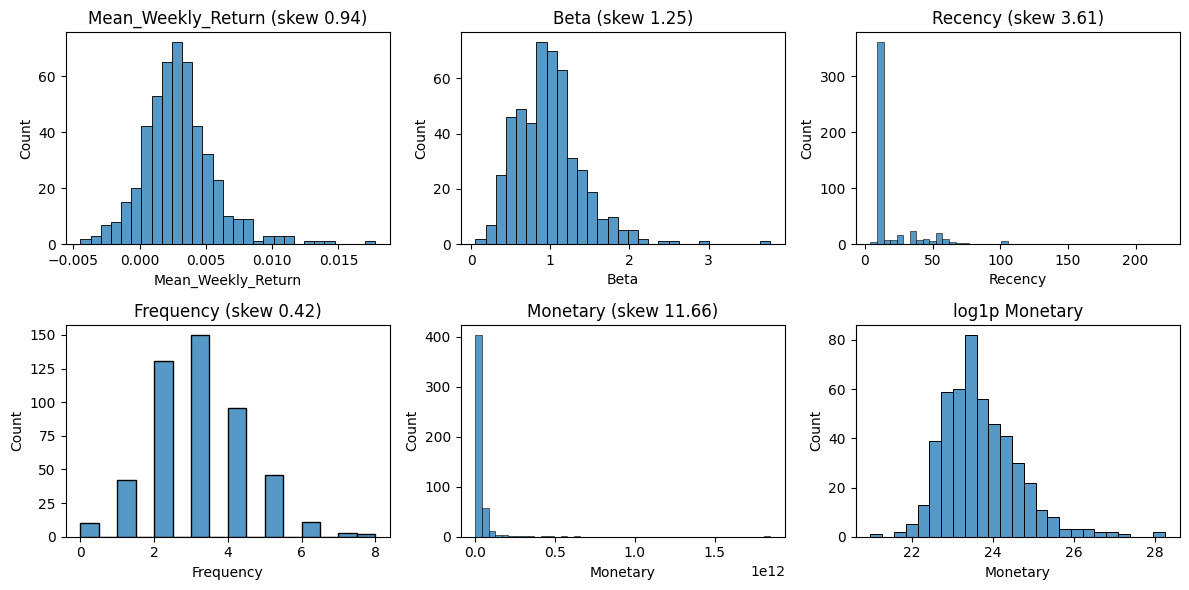

In [ ]:
# Plot the distributions
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(features[col], ax=ax)
    ax.set_title(f"{col} (skew {features[col].skew():.2f})")
sns.histplot(X_rfm["Monetary"], ax=axes[1, 2])
axes[1, 2].set_title("log1p Monetary")
plt.tight_layout()
plt.savefig("outputs/fig_distributions.png", dpi=150)
plt.show()

In [ ]:
# Standardise each matrix
X_rr_scaled = StandardScaler().fit_transform(X_rr)
X_rfm_scaled = StandardScaler().fit_transform(X_rfm)

print("Means:", X_rr_scaled.mean(axis=0).round(2), X_rfm_scaled.mean(axis=0).round(2))
print("Std:", X_rr_scaled.std(axis=0).round(2), X_rfm_scaled.std(axis=0).round(2))

Means: [-0. -0.] [ 0. -0.  0.]
Std: [1. 1.] [1. 1. 1.]


In [ ]:
# Task 2.2 Ward clustering for k from 2 to 8
def evaluate_ward(X_scaled):
    hierarchy = linkage(X_scaled, method="ward")
    rows = []
    for k in range(2, 9):
        labels = cut_tree(hierarchy, n_clusters=k).ravel()
        sizes = np.bincount(labels)
        rows.append({"k": k, "silhouette": round(silhouette_score(X_scaled, labels), 3),
                     "smallest_cluster": sizes.min(), "sizes": sorted(sizes.tolist(), reverse=True)})
    return hierarchy, pd.DataFrame(rows)

In [ ]:
hier_rr, ward_rr_table = evaluate_ward(X_rr_scaled)
hier_rfm, ward_rfm_table = evaluate_ward(X_rfm_scaled)

print("Ward risk and return")
print(ward_rr_table.to_string(index=False))
print("\nWard RFM")
print(ward_rfm_table.to_string(index=False))

Ward risk and return
 k  silhouette  smallest_cluster                             sizes
 2       0.508                36                         [455, 36]
 3       0.262                36                    [332, 123, 36]
 4       0.295                36               [176, 156, 123, 36]
 5       0.319                36           [176, 123, 111, 45, 36]
 6       0.324                 6        [176, 123, 111, 45, 30, 6]
 7       0.306                 6     [176, 123, 91, 45, 30, 20, 6]
 8       0.294                 6 [123, 107, 91, 69, 45, 30, 20, 6]

Ward RFM
 k  silhouette  smallest_cluster                             sizes
 2       0.357                93                         [398, 93]
 3       0.306                93                    [251, 147, 93]
 4       0.291                43                [208, 147, 93, 43]
 5       0.311                10            [208, 147, 83, 43, 10]
 6       0.319                10        [208, 127, 83, 43, 20, 10]
 7       0.297                1

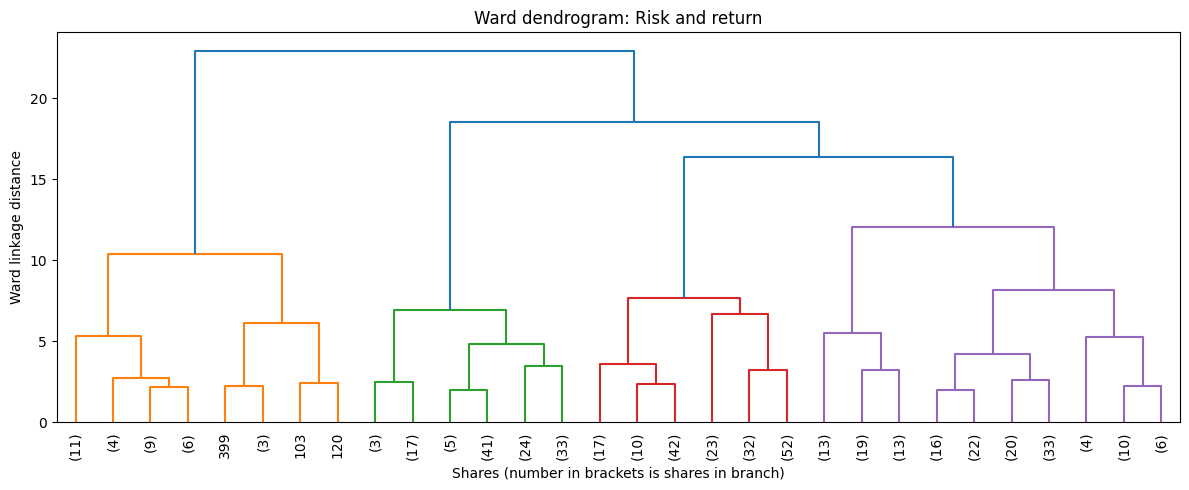

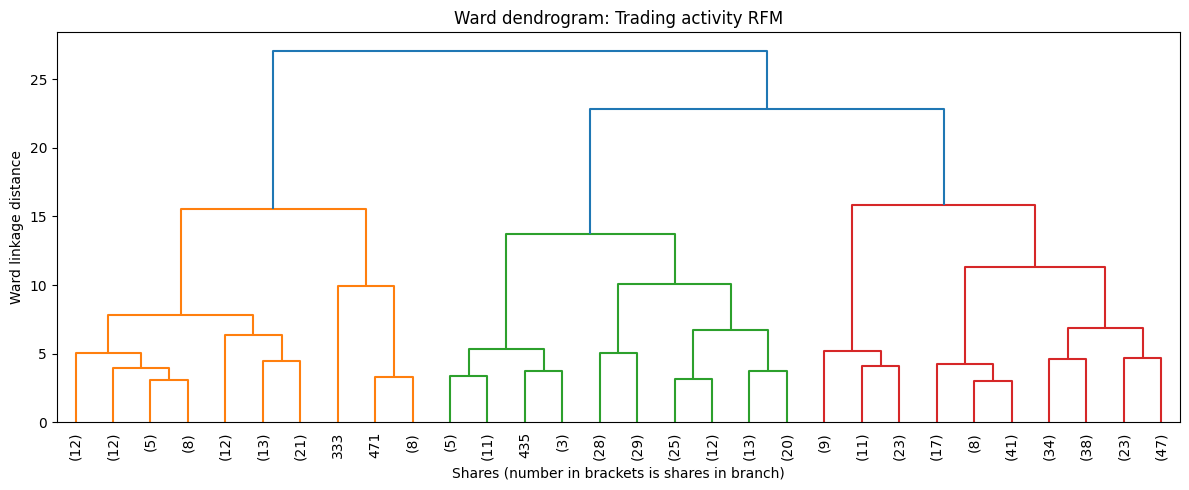

In [ ]:
# Dendrograms
for hier, name in [(hier_rr, "Risk and return"), (hier_rfm, "Trading activity RFM")]:
    plt.figure(figsize=(12, 5))
    dendrogram(hier, truncate_mode="lastp", p=30, leaf_rotation=90)
    plt.title(f"Ward dendrogram: {name}")
    plt.xlabel("Shares (number in brackets is shares in branch)")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(f"outputs/fig_dendrogram_{name.split()[0].lower()}.png", dpi=150)
    plt.show()

In [ ]:
# Choose k
def choose_k(table, n_shares):
    # smallest cluster must have at least 5 percent of shares
    feasible = table[table["smallest_cluster"] >= 0.05 * n_shares]
        # then pick the k with the best silhouette
    return int(feasible.sort_values("silhouette", ascending=False)["k"].iloc[0])

n = len(features)
k_rr = choose_k(ward_rr_table, n)
k_rfm = choose_k(ward_rfm_table, n)
print("Ward k risk and return:", k_rr)
print("Ward k RFM:", k_rfm)

Ward k risk and return: 2
Ward k RFM: 2


In [ ]:
features["Ward_RR"] = cut_tree(hier_rr, n_clusters=k_rr).ravel() + 1
features["Ward_RFM"] = cut_tree(hier_rfm, n_clusters=k_rfm).ravel() + 1

In [ ]:
# Task 2.3 K means for k from 2 to 8
def evaluate_kmeans(X_scaled):
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X_scaled)
        sizes = np.bincount(km.labels_)
        rows.append({"k": k, "inertia": round(km.inertia_, 1), "silhouette": round(silhouette_score(X_scaled, km.labels_), 3),
                     "smallest_cluster": sizes.min(), "sizes": sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows)

In [ ]:
km_rr_table = evaluate_kmeans(X_rr_scaled)
km_rfm_table = evaluate_kmeans(X_rfm_scaled)

print("K means risk and return")
print(km_rr_table.to_string(index=False))
print("\nK means RFM")
print(km_rfm_table.to_string(index=False))

K means risk and return
 k  inertia  silhouette  smallest_cluster                            sizes
 2    624.9       0.390               147                       [344, 147]
 3    472.4       0.321               122                  [204, 165, 122]
 4    372.8       0.324                39              [175, 156, 121, 39]
 5    313.2       0.339                18          [160, 129, 129, 55, 18]
 6    260.6       0.334                 7       [157, 127, 106, 51, 43, 7]
 7    224.9       0.335                 7     [153, 86, 74, 73, 50, 48, 7]
 8    192.5       0.355                 7 [137, 81, 77, 76, 44, 40, 29, 7]

K means RFM
 k  inertia  silhouette  smallest_cluster                             sizes
 2   1080.7       0.421                70                         [421, 70]
 3    809.3       0.324                64                    [273, 154, 64]
 4    617.9       0.340                60                [214, 122, 95, 60]
 5    522.0       0.357                11            [200, 

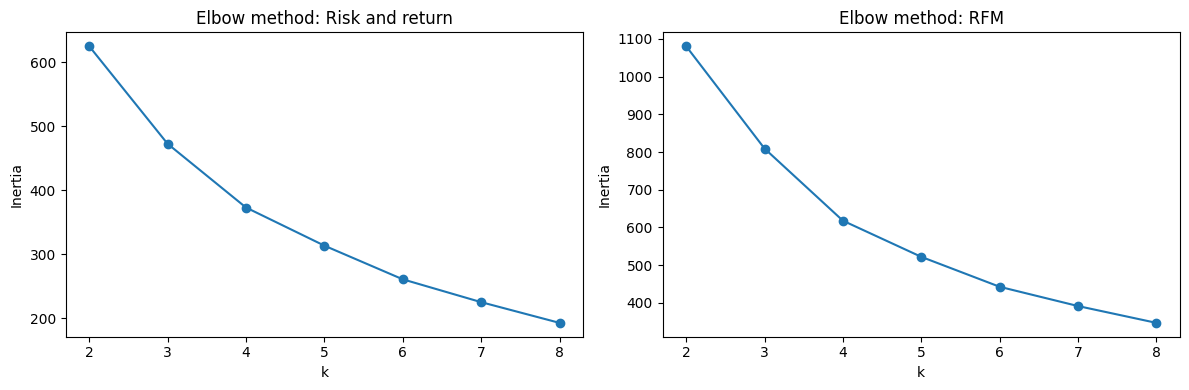

In [ ]:
# Elbow plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, table, name in [(axes[0], km_rr_table, "Risk and return"), (axes[1], km_rfm_table, "RFM")]:
    ax.plot(table["k"], table["inertia"], marker="o")
    ax.set_title(f"Elbow method: {name}")
    ax.set_xlabel("k")
    ax.set_ylabel("Inertia")
plt.tight_layout()
plt.savefig("outputs/fig_kmeans_elbow.png", dpi=150)
plt.show()

In [ ]:
kk_rr = choose_k(km_rr_table, n)
kk_rfm = choose_k(km_rfm_table, n)
print("K means k risk and return:", kk_rr)
print("K means k RFM:", kk_rfm)

features["KMeans_RR"] = KMeans(n_clusters=kk_rr, n_init=50, random_state=42).fit_predict(X_rr_scaled) + 1
features["KMeans_RFM"] = KMeans(n_clusters=kk_rfm, n_init=50, random_state=42).fit_predict(X_rfm_scaled) + 1

K means k risk and return: 2
K means k RFM: 2


In [ ]:
# Check that different seeds give the same clusters
for s in range(1, 6):
    other = KMeans(n_clusters=kk_rfm, n_init=50, random_state=s).fit_predict(X_rfm_scaled)
    print("Seed", s, "ARI:", round(adjusted_rand_score(features["KMeans_RFM"], other), 3))

Seed 1 ARI: 1.0
Seed 2 ARI: 1.0
Seed 3 ARI: 1.0
Seed 4 ARI: 1.0
Seed 5 ARI: 1.0


In [ ]:
# Task 2.4 Cluster profiles in original units
for sol in ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]:
    prof = features.groupby(sol)[cols].mean()
    prof["Mean_Weekly_Return"] = prof["Mean_Weekly_Return"] * 100
    prof["Monetary"] = prof["Monetary"] / 1e9
    prof.insert(0, "n_shares", features[sol].value_counts().sort_index())
    print(f"\n{sol} (return in %, monetary in USD billions)")
    print(prof.round(3))
    prof.round(4).to_csv(f"outputs/profile_{sol}.csv")


Ward_RR (return in %, monetary in USD billions)
         n_shares  Mean_Weekly_Return   Beta  Recency  Frequency  Monetary
Ward_RR                                                                   
1             455               0.242  0.940   19.921      2.969    34.301
2              36               0.902  1.519   28.000      3.333   109.308

KMeans_RR (return in %, monetary in USD billions)
           n_shares  Mean_Weekly_Return   Beta  Recency  Frequency  Monetary
KMeans_RR                                                                   
1               147               0.540  1.369   22.925      3.170    81.762
2               344               0.183  0.817   19.483      2.922    21.869

Ward_RFM (return in %, monetary in USD billions)
          n_shares  Mean_Weekly_Return   Beta  Recency  Frequency  Monetary
Ward_RFM                                                                   
1              398               0.289  0.974   12.332      3.211    38.425
2             

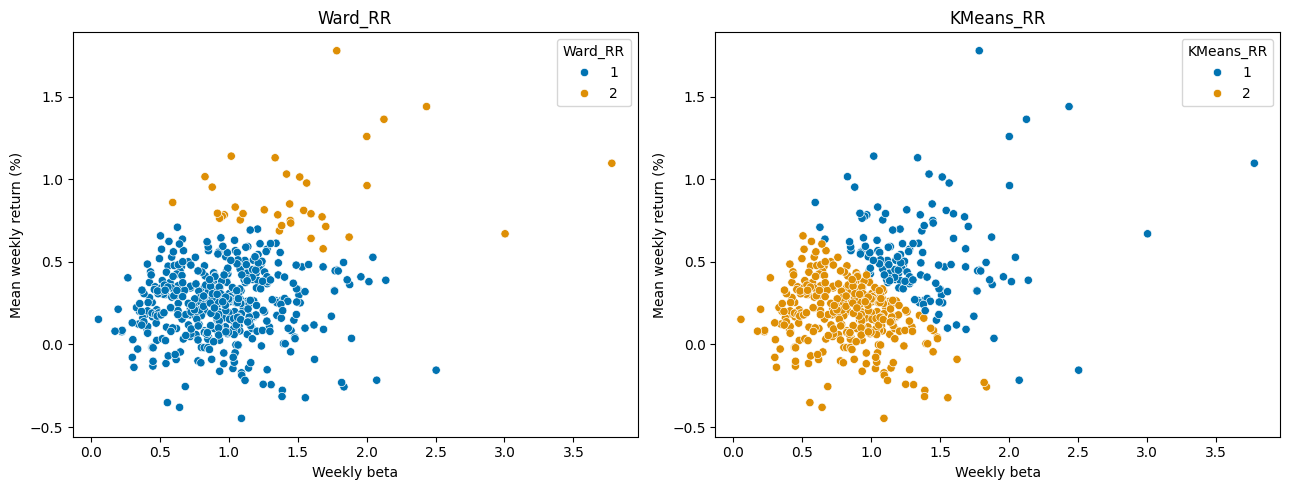

In [ ]:
# Scatter plot of risk and return clusters
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, sol in zip(axes, ["Ward_RR", "KMeans_RR"]):
    sns.scatterplot(x=features["Beta"], y=features["Mean_Weekly_Return"] * 100, hue=features[sol], palette="colorblind", ax=ax)
    ax.set_xlabel("Weekly beta")
    ax.set_ylabel("Mean weekly return (%)")
    ax.set_title(sol)
plt.tight_layout()
plt.savefig("outputs/fig_scatter_rr.png", dpi=150)
plt.show()

Explained variance: [0.456 0.339]


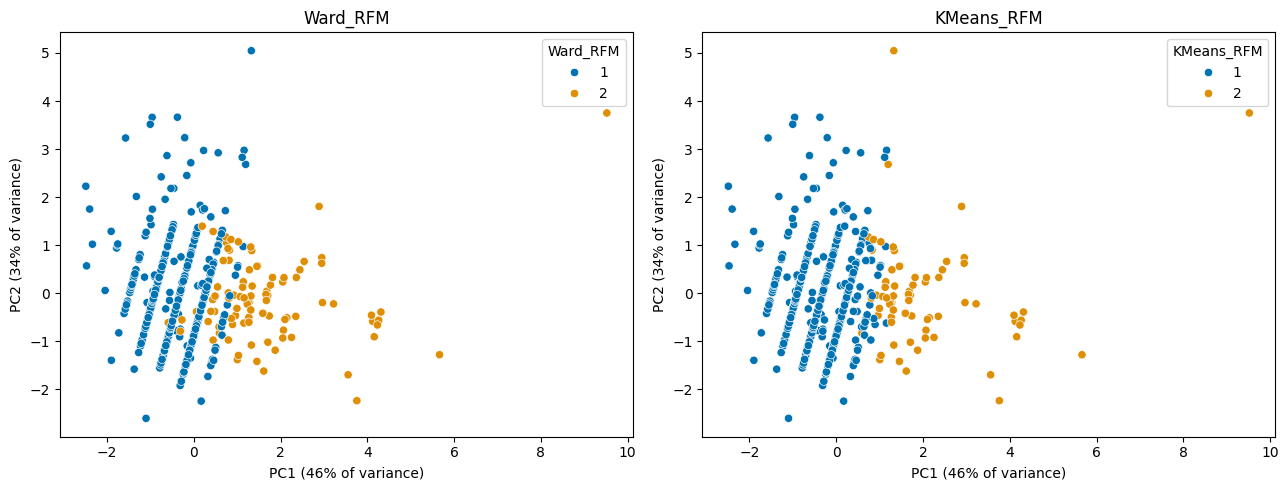

In [ ]:
# PCA plot of RFM clusters
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_rfm_scaled)
print("Explained variance:", pca.explained_variance_ratio_.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, sol in zip(axes, ["Ward_RFM", "KMeans_RFM"]):
    sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=features[sol], palette="colorblind", ax=ax)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
    ax.set_title(sol)
plt.tight_layout()
plt.savefig("outputs/fig_scatter_rfm_pca.png", dpi=150)
plt.show()

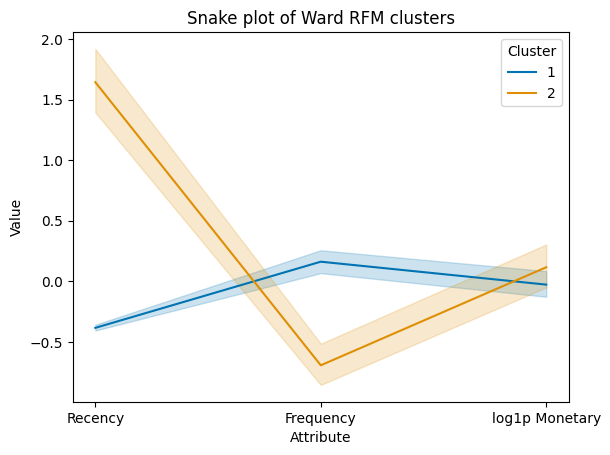

In [ ]:
# Snake plot
snake = pd.DataFrame(X_rfm_scaled, columns=["Recency", "Frequency", "log1p Monetary"], index=features.index)
snake["Cluster"] = features["Ward_RFM"]
melted = snake.melt(id_vars="Cluster", var_name="Attribute", value_name="Value")

sns.lineplot(x="Attribute", y="Value", hue="Cluster", data=melted, palette="colorblind")
plt.title("Snake plot of Ward RFM clusters")
plt.savefig("outputs/fig_snake_rfm.png", dpi=150)
plt.show()

In [ ]:
# Compare Ward and K means on the same shares
print("ARI risk and return:", round(adjusted_rand_score(features["Ward_RR"], features["KMeans_RR"]), 3))
print("ARI RFM:", round(adjusted_rand_score(features["Ward_RFM"], features["KMeans_RFM"]), 3))
pd.crosstab(features["Ward_RFM"], features["KMeans_RFM"])

ARI risk and return: 0.207
ARI RFM: 0.741


KMeans_RFM,1,2
Ward_RFM,,
1,396,2
2,25,68


                Recency  Frequency  log1p Monetary
Recency           1.000     -0.339           0.160
Frequency        -0.339      1.000           0.023
log1p Monetary    0.160      0.023           1.000


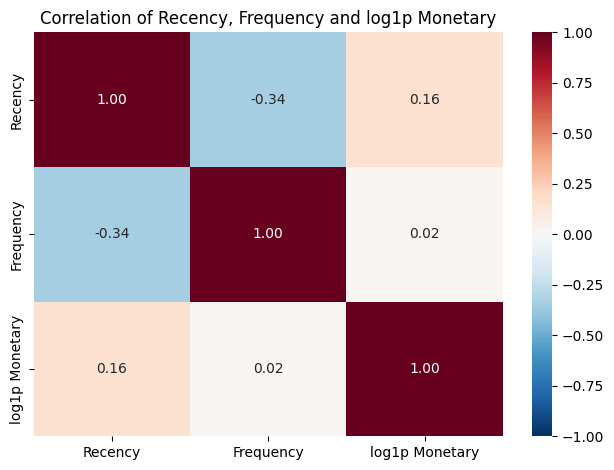

In [ ]:
# Task 2.5.1 Correlation between R, F and log1p M
corr = X_rfm.rename(columns={"Monetary": "log1p Monetary"}).corr()
print(corr.round(3))
corr.to_csv("outputs/rfm_correlation.csv")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation of Recency, Frequency and log1p Monetary")
plt.tight_layout()
plt.savefig("outputs/fig_rfm_correlation.png", dpi=150)
plt.show()

In [ ]:
# Task 2.5.2 Ward with R and F only
X_rf_scaled = StandardScaler().fit_transform(features[["Recency", "Frequency"]])
features["Ward_RF_only"] = cut_tree(linkage(X_rf_scaled, method="ward"), n_clusters=k_rfm).ravel() + 1

print("ARI with M vs without M:", round(adjusted_rand_score(features["Ward_RFM"], features["Ward_RF_only"]), 3))
pd.crosstab(features["Ward_RFM"], features["Ward_RF_only"], rownames=["With M"], colnames=["Without M"])

ARI with M vs without M: 0.952


Without M,1,2
With M,,
1,396,2
2,3,90


In [ ]:
# Traded value by cluster
for sol in ["Ward_RFM", "Ward_RF_only"]:
    tv = features.groupby(sol)["Monetary"].agg(["count", "median", "mean"])
    tv[["median", "mean"]] = tv[["median", "mean"]] / 1e9
    print(f"\n{sol} (USD billions)")
    print(tv.round(2))


Ward_RFM (USD billions)
          count  median   mean
Ward_RFM                      
1           398   15.57  38.43
2            93   20.85  45.69

Ward_RF_only (USD billions)
              count  median   mean
Ward_RF_only                      
1               399   15.46  37.90
2                92   20.95  48.06


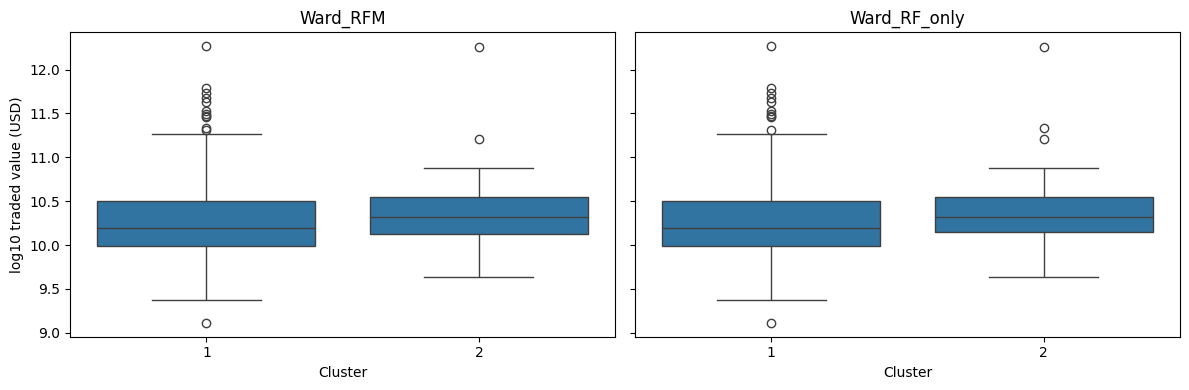

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sol in zip(axes, ["Ward_RFM", "Ward_RF_only"]):
    sns.boxplot(x=features[sol], y=np.log10(features["Monetary"]), ax=ax)
    ax.set_title(sol)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("log10 traded value (USD)")
plt.tight_layout()
plt.savefig("outputs/fig_monetary_removal.png", dpi=150)
plt.show()

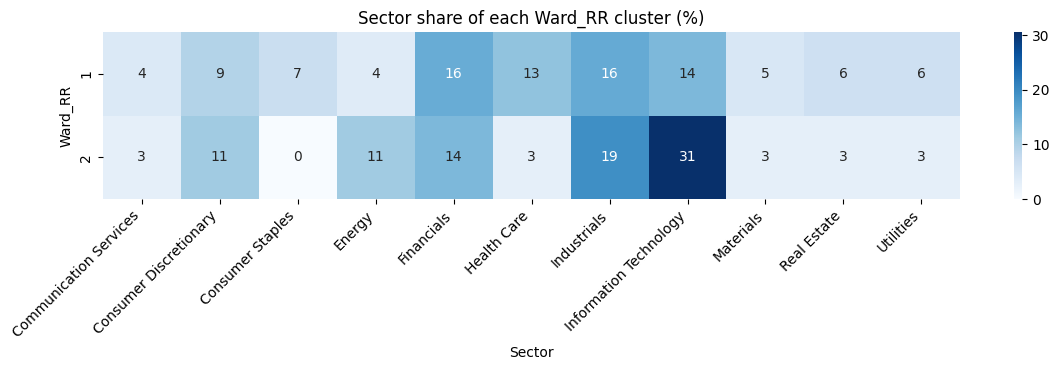

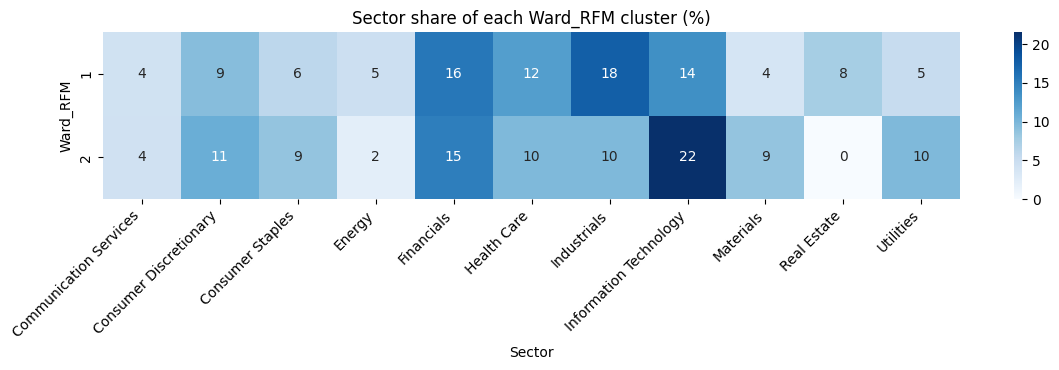

In [ ]:
# Task 3 Sector composition of clusters
for sol in ["Ward_RR", "Ward_RFM"]:
    sector_pct = pd.crosstab(features[sol], features["Sector"], normalize="index") * 100
    sector_pct.round(1).to_csv(f"outputs/sector_{sol}.csv")

    plt.figure(figsize=(12, 3 + 0.4 * sector_pct.shape[0]))
    sns.heatmap(sector_pct, annot=True, fmt=".0f", cmap="Blues")
    plt.title(f"Sector share of each {sol} cluster (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(f"outputs/fig_sector_{sol}.png", dpi=150)
    plt.show()

In [ ]:
# Compare risk and return clusters with RFM clusters
print("ARI:", round(adjusted_rand_score(features["Ward_RR"], features["Ward_RFM"]), 3))
pd.crosstab(features["Ward_RR"], features["Ward_RFM"])

ARI: 0.026


Ward_RFM,1,2
Ward_RR,,
1,371,84
2,27,9


In [ ]:
# Return correlation within and between clusters
corr_matrix = weekly_returns[features.index].corr().to_numpy(copy=True)
np.fill_diagonal(corr_matrix, np.nan)

labels = features["Ward_RR"].values
same = labels[:, None] == labels[None, :]

print("Average correlation all shares:", round(np.nanmean(corr_matrix), 3))
print("Within same cluster:", round(np.nanmean(np.where(same, corr_matrix, np.nan)), 3))
print("Between clusters:", round(np.nanmean(np.where(~same, corr_matrix, np.nan)), 3))

Average correlation all shares: 0.299
Within same cluster: 0.303
Between clusters: 0.272


In [ ]:
# Save the feature table
features.to_csv("outputs/feature_table.csv")
features.head()

,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary,Sector,Ward_RR,Ward_RFM,KMeans_RR,KMeans_RFM,Ward_RF_only
Share,,,,,,,,,,,
A,0.001121,1.074723,11,2,1.400180e+10,Health Care,1,1,2,1,1
AAPL,0.003930,1.174837,11,2,6.233034e+11,Information Technology,1,1,1,1,1
ABBV,0.003749,0.425367,11,3,6.837054e+10,Health Care,1,1,2,1,1
ABNB,0.001475,1.472709,11,3,3.652850e+10,Consumer Discretionary,1,1,1,1,1
ABT,0.000971,0.583543,11,1,3.523027e+10,Health Care,1,1,2,1,1


In [105]:
!pip list | grep -E "pandas|numpy|yfinance|scikit-learn|scipy|matplotlib|seaborn"

geopandas                             1.2.0
matplotlib                            3.10.0
matplotlib-inline                     0.2.2
matplotlib-venn                       1.1.2
numpy                                 2.4.6
pandas                                2.2.3
pandas-datareader                     0.11.1
pandas-gbq                            0.30.0
pandas-stubs                          2.2.3.250527
scikit-learn                          1.6.1
scipy                                 1.16.3
seaborn                               0.13.2
sklearn-pandas                        2.2.0
yfinance                              0.2.66
